# 03 · Shelf life: how much of the strawberries' life a trip uses

This notebook holds the formula behind the number the app ranks routes by: **% shelf life remaining on arrival**. It takes published measurements of how long strawberries last at different storage temperatures, treats shelf life as a **budget** that every hour of the trip spends (warmer hours spend more), and then tries the formula on the six real shipments. Unlike notebook 02, this part is a formula, not a trained model.

**Reads:** the published measurements (cited in the next cell) and `model/data/processed/strawberry_clean.csv` (made in notebook 01).

**Produces:** two functions, `shelf_life_days_at` and `shelf_life_remaining_pct`, plus a summary table. No files are saved.

# Strawberry shelf life vs storage temperature

**Source:** Yan et al., "Effect of Different Storage Temperature on Respiration Rate and Quality of Strawberry", *Journal of Refrigeration* (制冷学报), Issue 5, pp. 37-42.

Measured shelf life: 9 days at 0°C, 7 days at 5°C, 5 days at 10°C, 4 days at 15°C, 3 days at 20°C, 2 days at 25°C, 8 hours at 30°C.

**Cross-check:** the University of South Florida Food Quality Lab reports strawberry postharvest life of more than 9 days at a constant 1.5°C.

## Step 1: the published measurements

**What:** Stores the 7 measured points (temperature → shelf life in days) and plots them.

**Why:** The whole formula rests on these numbers, so we look at them first.

**Result:** Shelf life falls steadily from **9 days at 0°C** to 2 days at 25°C, then drops sharply to **8 hours at 30°C**.

 temp_c  shelf_life_days
      0             9.00
      5             7.00
     10             5.00
     15             4.00
     20             3.00
     25             2.00
     30             0.33


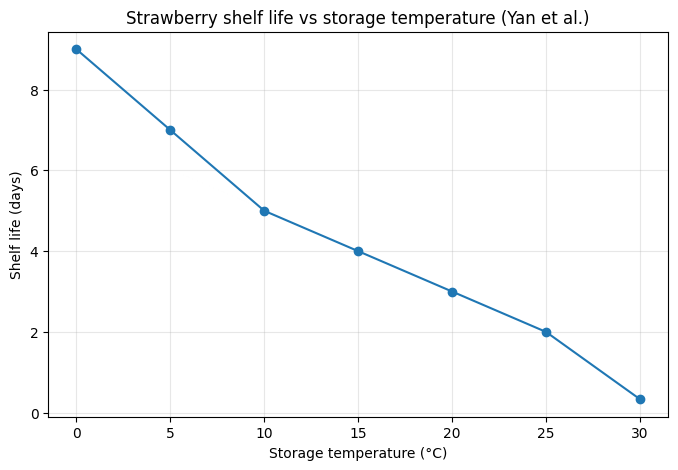

In [1]:
# Cell 1: the published measurements
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

shelf_life = pd.DataFrame({
    "temp_c": [0, 5, 10, 15, 20, 25, 30],
    "shelf_life_days": [9, 7, 5, 4, 3, 2, 8 / 24],  # 30°C: 8 hours
})
print(shelf_life.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(shelf_life["temp_c"], shelf_life["shelf_life_days"], marker="o")
ax.set_title("Strawberry shelf life vs storage temperature (Yan et al.)")
ax.set_xlabel("Storage temperature (°C)")
ax.set_ylabel("Shelf life (days)")
ax.grid(alpha=0.3)
plt.show()

## Step 2: shelf life at any temperature

**What:** Connects the measured points with straight lines (*linear interpolation*), so we can look up shelf life at temperatures in between, such as 2.3°C. Outside 0–30°C it holds the nearest end value.

**Why:** Trucks run at temperatures the study didn't measure exactly, and straight lines are the simplest method that passes through every measured point. The limits are a **choice, not data**: the study didn't test below 0°C or above 30°C.

**Result:** about 8.2 days at 2°C, 7.4 at 4°C, 5.8 at 8°C, and 4.6 at 12°C.

In [2]:
# Cell 2: shelf life at any temperature, by connecting the measured dots with straight lines
def shelf_life_days_at(temp_c):
    """Shelf life in days at a constant temperature (works on one number or an array)."""
    # np.interp holds the end values outside the data: below 0°C -> the 0°C value, above 30°C -> the
    # 30°C value. These are limits, not measurements: the study didn't test outside 0-30°C.
    return np.interp(temp_c, shelf_life["temp_c"], shelf_life["shelf_life_days"])


for t in [0, 1, 2, 3, 4, 8, 12, 30]:
    print(f"{t:>3} °C: {shelf_life_days_at(t):.2f} days")

  0 °C: 9.00 days
  1 °C: 8.60 days
  2 °C: 8.20 days
  3 °C: 7.80 days
  4 °C: 7.40 days
  8 °C: 5.80 days
 12 °C: 4.60 days
 30 °C: 0.33 days


## Step 3: shelf life as a budget

**What:** Splits a trip into equal time steps. Each step uses up *(step length ÷ shelf life at that step's temperature)* of the fruit's life. The steps are added up, and remaining = 100% − used, never below 0. The cell tests this on simple cases with known answers.

**Why:** This is the project's core idea: produce spoils because of temperature × time, and warmer hours spend the budget faster. The method assumes the losses simply **add up**, no matter in what order the temperatures happen. Built-in checks (`assert` lines) confirm two of the expected answers automatically.

**Result:**
- 5 days at 0°C → **44.4%** left (5 of 9 days used)
- 5 days at 2°C → 39.0% left
- 5 days at 10°C → **0%** left
- 4 days at 2°C + 6 hours at 15°C (a door left open) → 45.0% left

In [3]:
# Cell 3: shelf life used up during a trip, treating shelf life as a budget
def shelf_life_remaining_pct(temps_c, hours_per_step):
    """% of shelf life left after a series of equal time steps at the given temperatures."""
    temps_c = np.asarray(temps_c, dtype=float)
    # Each step uses (its length) / (total life at that temperature) of the fruit's life
    used = (hours_per_step / (shelf_life_days_at(temps_c) * 24)).sum()
    return max(0.0, 100 * (1 - used))


steps_per_day = 24  # 1-hour steps for the test cases
tests = {
    "5 days at 0°C (expect ~44%)": [0] * 5 * steps_per_day,
    "5 days at 2°C": [2] * 5 * steps_per_day,
    "5 days at 10°C (expect 0%)": [10] * 5 * steps_per_day,
    "4 days at 2°C + 6 hours at 15°C": [2] * 4 * steps_per_day + [15] * 6,
}
for name, temps in tests.items():
    print(f"{name:<34} {shelf_life_remaining_pct(temps, hours_per_step=1):5.1f}% left")

assert abs(shelf_life_remaining_pct([0] * 120, 1) - 100 * (1 - 5 / 9)) < 1e-9
assert shelf_life_remaining_pct([10] * 120, 1) < 1e-9  # not exactly 0: tiny rounding in the sum

5 days at 0°C (expect ~44%)         44.4% left
5 days at 2°C                       39.0% left
5 days at 10°C (expect 0%)           0.0% left
4 days at 2°C + 6 hours at 15°C     45.0% left


## Step 4: apply the formula to the real trucks

**What:** For each sensor, averages readings into 15-minute blocks and computes shelf life remaining at the end of its data, two ways:
- **(a)** counting the transit phase only
- **(b)** counting precool + transit, the full window

It then summarizes each shipment's mean and worst sensor.

**Why:**
- To see what the formula says about real trips, and whether the results are believable.
- The `handling_event` readings are **kept**, because the fruit really experienced that event. Partial sensors are **left out**, because they don't cover the whole trip.
- The 15-minute blocks are used for the same reason as in notebook 02: so fast-logging sensors don't count twice.

**Result:**
- **Transit only:** shipment means range from about 25% to 79% left. At the trucks' usual ~2°C, a trip uses roughly **12% of shelf life per day**, so **trip length decides most of the outcome**: Shipment 2 (2 days) ends with 78.5% left, Shipments 3 and 5 (6+ days) with about 25%.
- **Counting precool:** Shipments 2–6 lose a few percentage points more. **Shipment 1 drops to 0%** because of its 43-hour warm start at about 28°C.

In [4]:
# Cell 4: shelf life left at the end of each real sensor's data
from pathlib import Path

clean = pd.read_csv(Path("../data/processed/strawberry_clean.csv"), parse_dates=["time"])
full_sensors = clean[~clean["partial_sensor"]]  # handling_event rows kept: the fruit lived through it


def remaining_from_readings(sensor_rows):
    """Average one sensor's readings into 15-minute blocks, then apply the shelf-life budget."""
    blocks = sensor_rows.set_index("time")["temp_c"].resample("15min").mean().dropna()
    return shelf_life_remaining_pct(blocks.values, hours_per_step=0.25)


rows = []
for (shipment, pallet, layer), sensor_df in full_sensors.groupby(["shipment", "pallet", "layer"]):
    rows.append({
        "shipment": shipment,
        "pallet_layer": f"{pallet}_{layer}",
        "transit_only_pct": remaining_from_readings(sensor_df[sensor_df["phase"] == "transit"]),
        "full_window_pct": remaining_from_readings(sensor_df),  # precool + transit
    })
per_sensor = pd.DataFrame(rows)

summary = per_sensor.groupby("shipment").agg(
    transit_mean=("transit_only_pct", "mean"),
    transit_worst=("transit_only_pct", "min"),
    full_mean=("full_window_pct", "mean"),
    full_worst=("full_window_pct", "min"),
)
print("Shelf life remaining (%) at the end of each sensor's data:")
print(summary.round(1).to_string())

Shelf life remaining (%) at the end of each sensor's data:
          transit_mean  transit_worst  full_mean  full_worst
shipment                                                    
1                 45.7           42.0        0.0         0.0
2                 78.5           77.9       71.6        70.1
3                 27.2           22.8       23.0        18.6
4                 44.5           36.7       40.0        31.9
5                 24.6           20.8       15.6         8.2
6                 53.6           50.3       43.5        36.3


## Key findings

- **At the trucks' usual ~2°C, a trip uses about 12% of shelf life per day**, so trip length decides most of the result.
- **Position within a truck matters little:** the worst sensor is only 1–8 percentage points below its truck's average.
- **The precool phase usually costs a few percent.** Shipment 1's 43-hour warm start would use about 2.5 full shelf lives (checked separately), most likely because the sensors were logging warm air before the fruit was packed.
- **S2_Middle_Top's handling event shows no extra loss:** its warm spike was short, and the −6.5°C dip is scored as if it were 0°C.

## Limitations

- **One study, 7 data points**, joined with straight lines. Other varieties and conditions may differ. The USF figure (more than 9 days at 1.5°C) is consistent with it.
- **No freezing damage:** temperatures below 0°C are treated as ideal storage, but strawberries freeze at around −1°C.
- **Above 30°C**, shelf life is held at 8 hours.
- **Assumptions:** fruit starts at 100%, and losses add up regardless of order.
- **Gaps:** 15-minute blocks with no readings are dropped, which slightly undercounts trip time.